Оригінальні маски мають області які пересікаються. Тому для даного досліду розмічені маски будуть обєднані та штучно розділені на 3 сети.
1. Тренувальний
2. Тестовий
3. Валідаційний

Усі дані будуть розділені на 2 частини 80% та 20%. В свою чергу 80% буде розідлено на 2 частини: 
- перша частина буде використовуватись як вибірка для тренувальних даних - сюди віднесемо 50% усіх даних
- друга частина буде використовуватись для вибору найкращої конфігурації параметрів класифікатора

20%  які були відібрані на початку не будуть використовуватись при підборі параметрів і будуть використані лише вкінці
для реальної оцінки роботи класифікатора. Дані будуть розподілені рівномірно та вибрані випадковим чином.

In [1]:
#%pip install scikit-learn

[*] Завантаження кольорових масок та обробка...

[SS1] Статистика розподілу пікселів:
  - Тренувальний набір (Train): 77669 пікселів
  - Валідаційний набір (Val):   46602 пікселів
  - Тестовий набір (Test):      31068 пікселів
  - Загальна кількість:         155339 пікселів
[*] Файли масок та Ground Truth для SS1 вже існують. Пропускаємо перезапис.

[SS2] Статистика розподілу пікселів:
  - Тренувальний набір (Train): 40989 пікселів
  - Валідаційний набір (Val):   24594 пікселів
  - Тестовий набір (Test):      16396 пікселів
  - Загальна кількість:         81979 пікселів
[*] Файли масок та Ground Truth для SS2 вже існують. Пропускаємо перезапис.


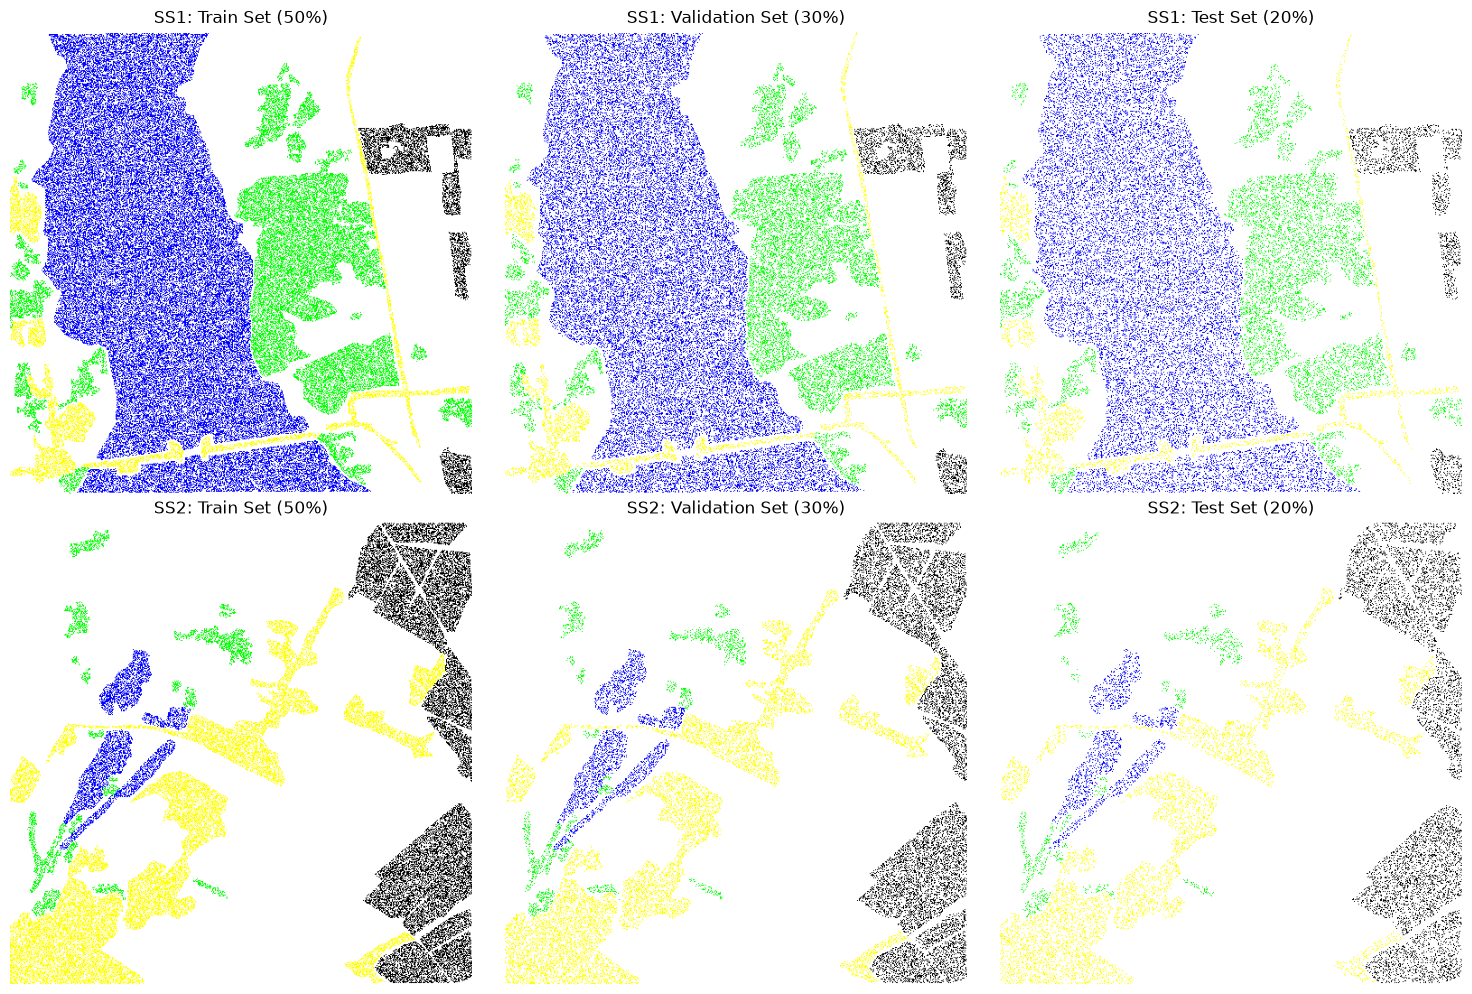


[+] Обробку та візуалізацію завершено.


In [2]:
import cv2
import numpy as np
import os
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

def prepare_and_save_visual_splits_rgb(data_dir="data", test_size=0.2, train_fraction=0.5, random_state=42):
    """
    Зчитує кольорові BMP-маски, об'єднує їх, класифікує за кольором,
    розбиває на Train, Validation та Test, зберігає маски на диск (включно з Ground Truth) та візуалізує.
    """
    print("[*] Завантаження кольорових масок та обробка...")
    
    image_pairs = [
        {"img": "SS1.bmp", "mask": "Etalon1.bmp", "samples": "Samples1.bmp"},
        {"img": "SS2.bmp", "mask": "Etalon2.bmp", "samples": "Samples2.bmp"}
    ]
    
    fig, axes = plt.subplots(len(image_pairs), 3, figsize=(15, 5 * len(image_pairs)))
    if len(image_pairs) == 1:
        axes = np.array([axes])
        
    for i, pair in enumerate(image_pairs):
        mask_path = os.path.join(data_dir, pair["mask"])
        samples_path = os.path.join(data_dir, pair["samples"])
        base_name = os.path.splitext(pair["img"])[0]
        
        # Читаємо як кольорові зображення (BGR)
        mask_bgr = cv2.imread(mask_path, cv2.IMREAD_COLOR)
        samples_bgr = cv2.imread(samples_path, cv2.IMREAD_COLOR)
        
        if mask_bgr is None:
            print(f"[!] Попередження: Не вдалося завантажити {mask_path}")
            continue
            
        def color_to_class(bgr_img):
            classes = np.zeros(bgr_img.shape[:2], dtype=np.uint8)
            b, g, r = bgr_img[:,:,0], bgr_img[:,:,1], bgr_img[:,:,2]
            
            white_bg = (r > 200) & (g > 200) & (b > 200)
            blue_water = (b > 150) & (r < 100) & (g < 100)
            green_veg = (g > 150) & (r < 100) & (b < 100)
            black_soil = (r < 50) & (g < 50) & (b < 50) & ~white_bg
            yellow_urban = (r > 150) & (g > 150) & (b < 100)
            
            classes[blue_water] = 1
            classes[green_veg] = 2
            classes[black_soil] = 3
            classes[yellow_urban] = 4
            return classes

        mask_classes = color_to_class(mask_bgr)
        
        if samples_bgr is not None:
            samples_classes = color_to_class(samples_bgr)
            merged_classes = np.where(samples_classes > 0, samples_classes, mask_classes)
        else:
            merged_classes = mask_classes
            
        h, w = merged_classes.shape
        
        valid_coords = np.argwhere(merged_classes > 0)
        valid_labels = merged_classes[valid_coords[:, 0], valid_coords[:, 1]]
        
        unique_classes, counts = np.unique(valid_labels, return_counts=True)
        rare_classes = unique_classes[counts < 2]
        
        if len(rare_classes) > 0:
            print(f"[!] Увага для {pair['mask']}: виключено класи з кількістю < 2: {rare_classes}")
            mask_filter = ~np.isin(valid_labels, rare_classes)
            valid_coords = valid_coords[mask_filter]
            valid_labels = valid_labels[mask_filter]
            
        if len(valid_labels) == 0:
            print(f"[!] Помилка: Не знайдено валідних розмічених пікселів у {pair['mask']}")
            continue
        
        idx_pool, idx_test = train_test_split(
            np.arange(len(valid_labels)), 
            test_size=test_size, 
            stratify=valid_labels, 
            random_state=random_state
        )
        
        relative_train_size = train_fraction / (1.0 - test_size)
        idx_train, idx_val = train_test_split(
            idx_pool, 
            train_size=relative_train_size, 
            stratify=valid_labels[idx_pool], 
            random_state=random_state
        )
        
        def classes_to_color(class_map):
            colored = np.zeros((*class_map.shape, 3), dtype=np.uint8)
            colored[class_map == 0] = [255, 255, 255] # Білий (фон)
            colored[class_map == 1] = [255, 0, 0]     # Синій (вода)
            colored[class_map == 2] = [0, 255, 0]     # Зелений (рослинність)
            colored[class_map == 3] = [0, 0, 0]       # Чорний (ґрунт)
            colored[class_map == 4] = [0, 255, 255]   # Жовтий (урбанізація)
            return colored

        train_map = np.zeros((h, w), dtype=np.uint8)
        val_map = np.zeros((h, w), dtype=np.uint8)
        test_map = np.zeros((h, w), dtype=np.uint8)
        
        train_coords = valid_coords[idx_train]
        train_map[train_coords[:, 0], train_coords[:, 1]] = merged_classes[train_coords[:, 0], train_coords[:, 1]]
        
        val_coords = valid_coords[idx_val]
        val_map[val_coords[:, 0], val_coords[:, 1]] = merged_classes[val_coords[:, 0], val_coords[:, 1]]
        
        test_coords = valid_coords[idx_test]
        test_map[test_coords[:, 0], test_coords[:, 1]] = merged_classes[test_coords[:, 0], test_coords[:, 1]]
        
        # Статистика розподілу пікселів
        print(f"\n[{base_name}] Статистика розподілу пікселів:")
        print(f"  - Тренувальний набір (Train): {len(train_coords)} пікселів")
        print(f"  - Валідаційний набір (Val):   {len(val_coords)} пікселів")
        print(f"  - Тестовий набір (Test):      {len(test_coords)} пікселів")
        print(f"  - Загальна кількість:         {len(valid_labels)} пікселів")
        
        # Шляхи до файлів (включно з Ground Truth)
        train_path = os.path.join(data_dir, f"{base_name}_train_mask.bmp")
        val_path = os.path.join(data_dir, f"{base_name}_val_mask.bmp")
        test_path = os.path.join(data_dir, f"{base_name}_test_mask.bmp")
        gt_path = os.path.join(data_dir, f"{base_name}_ground_truth.bmp")
        
        # Перевірка наявності всіх файлів
        if os.path.exists(train_path) and os.path.exists(val_path) and os.path.exists(test_path) and os.path.exists(gt_path):
            print(f"[*] Файли масок та Ground Truth для {base_name} вже існують. Пропускаємо перезапис.")
        else:
            cv2.imwrite(train_path, classes_to_color(train_map))
            cv2.imwrite(val_path, classes_to_color(val_map))
            cv2.imwrite(test_path, classes_to_color(test_map))
            cv2.imwrite(gt_path, classes_to_color(merged_classes))
            print(f"[+] Нові маски та Ground Truth для {base_name} успішно збережено.")
        
        # Відображення в Jupyter
        axes[i, 0].imshow(cv2.cvtColor(classes_to_color(train_map), cv2.COLOR_BGR2RGB))
        axes[i, 0].set_title(f"{base_name}: Train Set (50%)")
        axes[i, 0].axis('off')
        
        axes[i, 1].imshow(cv2.cvtColor(classes_to_color(val_map), cv2.COLOR_BGR2RGB))
        axes[i, 1].set_title(f"{base_name}: Validation Set (30%)")
        axes[i, 1].axis('off')
        
        axes[i, 2].imshow(cv2.cvtColor(classes_to_color(test_map), cv2.COLOR_BGR2RGB))
        axes[i, 2].set_title(f"{base_name}: Test Set (20%)")
        axes[i, 2].axis('off')

    plt.tight_layout()
    plt.show()
    print("\n[+] Обробку та візуалізацію завершено.")

if __name__ == "__main__":
    prepare_and_save_visual_splits_rgb()

## Двоетапна просторова блочна ізоляція масок (Two-Stage Spatially Disjoint Block Sampling) з буферними зонами та динамічним балансуванням класів

У задачах дистанційного зондування Землі (ДЗЗ) пікселі, розташовані поруч, мають високу просторову автокореляцію (*spatial autocorrelation*). Окрім того, оператори розрахунку просторово-частотних ознак (Sobel 3×3, ДКП 5×5, LBP $R=3$, локальна ентропія $R=3..4$) володіють рецептивним полем (*receptive field*) радіусом до 4 пікселів навколо цільового пікселя.

Звичайний випадковий попіксельний поділ (*pixel-random split*) призводить до критичного **просторового витоку даних (*Spatial Data Leakage*)**: вікна ознак тренувальних та тестових пікселів перетинаються на 80–90%, через що оцінки точності класифікації ($F_1$-score) штучно завищуються.

### Алгоритм двоетапного блочного розбиття з буферними зонами та покласовим балансуванням:

#### Етап 1: Генерація просторово відокремленого пулу навчання (~30%) та тесту (~70%)
1. **Параметри блоків та буфера:**
   - `patch_size = 70` (квадратні блоки 70×70 пікселів для навчання).
   - `buffer_size = 5` (смуга відчуження 5 пікселів навколо кожного тренувального блоку, що відповідає структурному елементу 11×11 для відстані Чебишова $L_\infty > 5$ px).
   - `target_train_ratio = 0.30` (~30% розмічених пікселів до пулу навчання, решта ~60–70% — до тесту).
   - `class_min_ratio = 0.20`, `class_max_ratio = 0.40` (коридор допустимої частки кожного класу в пулі навчання: від 20% до 40%).
2. **Фаза A (Початковий набір):** Випадковими проходами вікон 70×70 набирається близько 25% розмічених пікселів із класів, які не перевищують ліміт.
3. **Фаза B (Цільове доведення до 30% з балансуванням):** Контролюється поточний розподіл класів. Якщо певний клас має менше 20%, алгоритм цілеспрямовано обирає якірні пікселі цього класу та застосовує адаптивне зміщення (*offset slicing*), запобігаючи поглинанню понад 40% компактних класів (наприклад, водних об'єктів чи ґрунту).
4. **Контроль цілісності буфера та захист тесту:** Жоден клас у тестовій вибірці не може бути зменшений нижче 50% від його початкового обсягу внаслідок накладання буферних зон.
5. **Автоматичні перезапуски (Restarts):** Якщо після досягнення 30% будь-який клас виходить за межі [20%, 40%], генерація перезапускається з новим випадковим зерном (до 50 спроб). За відсутності 100% ідеального варіанту обирається спроба з мінімальним відхиленням.
6. **Сувора перевірка нульового перетину:** Виконується верифікація за допомогою `scipy.ndimage.binary_dilation` (структурний елемент 11×11) — кількість пересічних пікселів між `train_pool` та `test` строго дорівнює 0.

---

#### Етап 2: Підвибіркове семплювання з пулу навчання для кривих навчання (Learning Curves)
- Тестова вибірка (`test_mask`) залишається **100% фіксованою** для всіх подальших експериментів.
- Для дослідження кривих навчання (*Learning Curves*) функція `sample_from_train_pool(train_pool_mask, fraction, random_seed)` виконує стратифіковане попіксельне семплювання всередині `train_pool_mask` для заданої частки (`fraction`: 0.1, 0.25, 0.5, 0.75, 1.0).

[*] Завантаження кольорових масок та двоетапне просторове розбиття (Spatial Block Split)...

[+] Нові просторові маски для SS1 успішно згенеровано та збережено (Спроба 0, Ідеальний баланс: True).

[SS1] Статистика просторового розподілу:
  - Тренувальний пул (Train Pool, блоки 70x70): 47938 пікселів (30.86%)
  - Буферна зона відчуження (Buffer, 5 px):         14077 пікселів (9.06%)
  - Тестовий набір (Test, ізольований):                 93324 пікселів (60.08%)
  - Загальна кількість розмічених пікселів (GT):        155339 пікселів
  - Верифікація рецептивного поля (Overlap Count, строго 0): 0
  Покласовий розподіл (Train / Test):
    * Вода         (Клас 1): Всього=96864 | Train=25868 (26.7%) | Buffer=7858 (8.1%) | Test=63138 (65.2%)
    * Рослинність  (Клас 2): Всього=38163 | Train=14688 (38.5%) | Buffer=3991 (10.5%) | Test=19484 (51.1%)
    * Ґрунт        (Клас 3): Всього= 8063 | Train= 2820 (35.0%) | Buffer= 919 (11.4%) | Test= 4324 (53.6%)
    * Урбанізація  (Клас 4): Всього=12249 

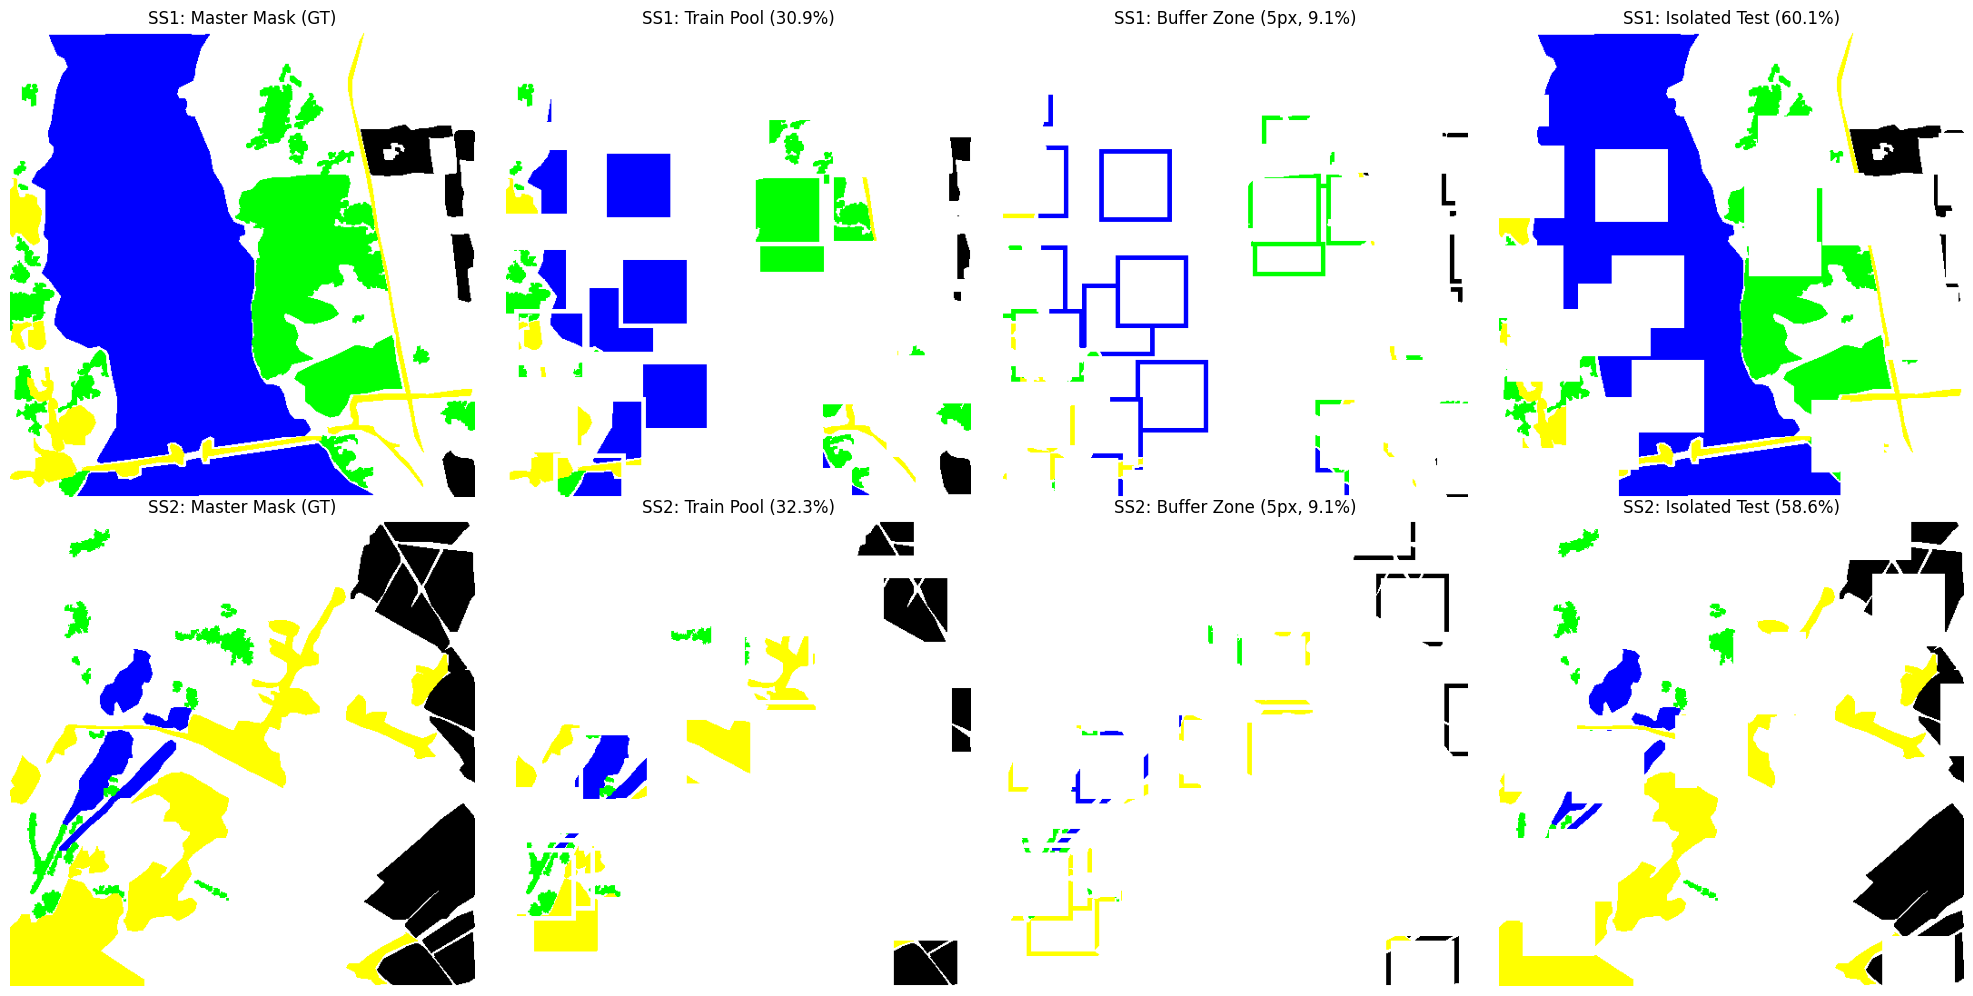

In [3]:
import cv2
import numpy as np
import os
import scipy.ndimage
import matplotlib.pyplot as plt

def color_to_class(bgr_img):
    classes = np.zeros(bgr_img.shape[:2], dtype=np.uint8)
    b, g, r = bgr_img[:,:,0], bgr_img[:,:,1], bgr_img[:,:,2]
    white_bg = (r > 200) & (g > 200) & (b > 200)
    blue_water = (b > 150) & (r < 100) & (g < 100)
    green_veg = (g > 150) & (r < 100) & (b < 100)
    black_soil = (r < 50) & (g < 50) & (b < 50) & ~white_bg
    yellow_urban = (r > 150) & (g > 150) & (b < 100)
    classes[blue_water] = 1
    classes[green_veg] = 2
    classes[black_soil] = 3
    classes[yellow_urban] = 4
    return classes

def classes_to_color(class_map):
    colored = np.zeros((*class_map.shape, 3), dtype=np.uint8)
    colored[class_map == 0] = [255, 255, 255] # Білий (фон / нерозмічено)
    colored[class_map == 1] = [255, 0, 0]     # Синій (вода)
    colored[class_map == 2] = [0, 255, 0]     # Зелений (рослинність)
    colored[class_map == 3] = [0, 0, 0]       # Чорний (ґрунт)
    colored[class_map == 4] = [0, 255, 255]   # Жовтий (урбанізація)
    return colored

def two_stage_spatial_split(
    gt_mask,
    window_size=70,
    buffer_margin=5,
    initial_target_ratio=0.25,
    target_train_ratio=0.30,
    class_min_ratio=0.20,
    class_max_ratio=0.40,
    random_seed=42,
    max_restarts=50,
    max_steps_per_attempt=150
):
    """
    Двоетапний просторовий блочний алгоритм розбиття масок із буферними зонами
    та покласовим балансуванням (Two-Stage Spatially Disjoint Block Sampling).
    """
    H, W = gt_mask.shape
    unique_classes = [int(c) for c in np.unique(gt_mask) if c > 0]
    total_class_counts = {c: int(np.sum(gt_mask == c)) for c in unique_classes}
    total_gt_pixels = sum(total_class_counts.values())
    class_indices = {c: (gt_mask == c) for c in unique_classes}
    struct_elem = cv2.getStructuringElement(cv2.MORPH_RECT, (2 * buffer_margin + 1, 2 * buffer_margin + 1))
    
    best_candidate = None
    best_deviation = float('inf')
    
    for attempt in range(max_restarts):
        seed = random_seed + attempt
        rng = np.random.RandomState(seed)
        state_map = np.zeros((H, W), dtype=np.uint8) # 0: test, 1: train_pool, 2: buffer
        current_train_counts = {c: 0 for c in unique_classes}
        class_attempts = {c: 0 for c in unique_classes}
        consecutive_rejects = 0
        step = 0
        
        while step < max_steps_per_attempt and consecutive_rejects < 40:
            step += 1
            train_ratio = sum(current_train_counts.values()) / total_gt_pixels
            
            # Фаза A: перші проходи вікном 70х70 до набору ~25% розмічених пікселів
            if train_ratio < initial_target_ratio:
                eligible = [c for c in unique_classes if (current_train_counts[c] / total_class_counts[c]) < 0.35]
                if not eligible:
                    eligible = [c for c in unique_classes if (current_train_counts[c] / total_class_counts[c]) < class_max_ratio]
                if not eligible:
                    break
                c_target = rng.choice(eligible)
            else:
                # Фаза B: покласове балансування для доведення до 30% у межах 20%–40%
                all_min = all(current_train_counts[c] / total_class_counts[c] >= class_min_ratio for c in unique_classes)
                if train_ratio >= target_train_ratio and all_min:
                    break
                under_min = [c for c in unique_classes if (current_train_counts[c] / total_class_counts[c]) < class_min_ratio]
                if under_min:
                    c_target = min(under_min, key=lambda c: current_train_counts[c] / total_class_counts[c])
                else:
                    eligible = [c for c in unique_classes if (current_train_counts[c] / total_class_counts[c]) < 0.38]
                    if not eligible:
                        break
                    c_target = rng.choice(eligible)
                    
            available_coords = np.argwhere((gt_mask == c_target) & (state_map == 0))
            if len(available_coords) == 0:
                consecutive_rejects += 1
                continue
                
            y_anchor, x_anchor = available_coords[rng.randint(len(available_coords))]
            k_att = class_attempts[c_target]
            
            # Адаптивне крайове зміщення (corner slicing) для компактних малих класів
            if k_att > 10:
                off_y = rng.randint(window_size - 15, window_size) if rng.rand() < 0.5 else rng.randint(0, 15)
                off_x = rng.randint(window_size - 15, window_size) if rng.rand() < 0.5 else rng.randint(0, 15)
                y0 = y_anchor - off_y
                x0 = x_anchor - off_x
            else:
                dy = rng.randint(-window_size // 2, window_size // 2 + 1)
                dx = rng.randint(-window_size // 2, window_size // 2 + 1)
                y0 = y_anchor - window_size // 2 + dy
                x0 = x_anchor - window_size // 2 + dx
                
            y1, x1 = max(0, y0), max(0, x0)
            y2, x2 = min(H, y0 + window_size), min(W, x0 + window_size)
            
            patch_candidate = np.zeros((H, W), dtype=bool)
            patch_candidate[y1:y2, x1:x2] = (state_map[y1:y2, x1:x2] == 0) & (gt_mask[y1:y2, x1:x2] > 0)
            
            if not np.any(patch_candidate[class_indices[c_target]]):
                class_attempts[c_target] += 1
                consecutive_rejects += 1
                continue
                
            tentative_train_mask = (state_map == 1) | patch_candidate
            dilated_train = cv2.dilate(tentative_train_mask.astype(np.uint8), struct_elem).astype(bool)
            tentative_test_mask = (gt_mask > 0) & np.logical_not(dilated_train)
            
            # Критерії валідації перед фіксацією
            reject = False
            for c in unique_classes:
                new_tr = int(np.sum(tentative_train_mask[class_indices[c]]))
                new_te = int(np.sum(tentative_test_mask[class_indices[c]]))
                tot_c = total_class_counts[c]
                # Заборонено перевищувати class_max_ratio (40%)
                if new_tr / tot_c > class_max_ratio:
                    reject = True
                    break
                # Заборонено скорочувати тестові пікселі класу нижче 50%
                if new_te / tot_c < 0.50:
                    reject = True
                    break
                    
            if reject:
                class_attempts[c_target] += 1
                consecutive_rejects += 1
            else:
                class_attempts[c_target] = 0
                consecutive_rejects = 0
                state_map[tentative_train_mask] = 1
                tentative_buffer_mask = dilated_train & np.logical_not(tentative_train_mask) & (gt_mask > 0)
                state_map[tentative_buffer_mask] = 2
                for c in unique_classes:
                    current_train_counts[c] = int(np.sum(tentative_train_mask[class_indices[c]]))
                    
        final_train_r = sum(current_train_counts.values()) / total_gt_pixels
        all_min = all(current_train_counts[c] / total_class_counts[c] >= class_min_ratio for c in unique_classes)
        all_max = all(current_train_counts[c] / total_class_counts[c] <= class_max_ratio for c in unique_classes)
        is_ideal = (0.28 <= final_train_r <= 0.33) and all_min and all_max
        
        # Метрика відхилення від ідеального коридору [20%, 40%]
        ratios = [current_train_counts[c] / total_class_counts[c] for c in unique_classes]
        dev = sum(max(0.0, class_min_ratio - r) + max(0.0, r - class_max_ratio) for r in ratios)
        dev += abs(final_train_r - target_train_ratio)
        
        if dev < best_deviation:
            best_deviation = dev
            best_candidate = (state_map.copy(), current_train_counts.copy(), attempt, is_ideal, final_train_r)
            
        if is_ideal:
            break
            
    final_state, final_counts, att, ideal, r = best_candidate
    train_pool_mask = np.where(final_state == 1, gt_mask, 0)
    test_mask = np.where(final_state == 0, gt_mask, 0)
    buffer_mask = np.where(final_state == 2, gt_mask, 0)
    
    # Сувора перевірка відсутності перетину з 11x11 структурним елементом (Chebyshev R=5)
    scipy_dil = scipy.ndimage.binary_dilation(train_pool_mask > 0, structure=np.ones((11, 11), dtype=bool))
    overlap_count = int(np.sum(scipy_dil & (test_mask > 0)))
    
    return train_pool_mask, test_mask, buffer_mask, overlap_count, att, ideal

def sample_from_train_pool(train_pool_mask, fraction=1.0, random_seed=42):
    """
    Етап 2: Стратифіковане випадкове попіксельне підвибіркове семплювання з train_pool_mask
    для побудови кривих навчання (Learning Curves).
    Тестова маска залишається 100% незмінною.
    """
    if fraction >= 1.0:
        return train_pool_mask.copy()
    if fraction <= 0.0:
        raise ValueError("fraction must be in range (0.0, 1.0]")
        
    rng = np.random.RandomState(random_seed)
    active_mask = np.zeros_like(train_pool_mask)
    classes = [int(c) for c in np.unique(train_pool_mask) if c > 0]
    for c in classes:
        coords = np.argwhere(train_pool_mask == c)
        n_samples = max(1, int(round(len(coords) * fraction)))
        chosen_idx = rng.choice(len(coords), size=n_samples, replace=False)
        chosen_coords = coords[chosen_idx]
        active_mask[chosen_coords[:, 0], chosen_coords[:, 1]] = c
    return active_mask

def prepare_and_save_spatial_splits_rgb(
    data_dir="data",
    window_size=70,
    buffer_margin=5,
    initial_target_ratio=0.25,
    target_train_ratio=0.30,
    class_min_ratio=0.20,
    class_max_ratio=0.40,
    random_seed=42,
    force_regenerate=False
):
    """
    Формує та зберігає просторово ізольовані маски навчання (~30%), тесту (~70%)
    та буферної зони відчуження (5 px).
    """
    print("[*] Завантаження кольорових масок та двоетапне просторове розбиття (Spatial Block Split)...\n")
    
    image_pairs = [
        {"img": "SS1.bmp", "mask": "Etalon1.bmp", "samples": "Samples1.bmp"},
        {"img": "SS2.bmp", "mask": "Etalon2.bmp", "samples": "Samples2.bmp"}
    ]
    
    fig, axes = plt.subplots(len(image_pairs), 4, figsize=(20, 5 * len(image_pairs)))
    if len(image_pairs) == 1:
        axes = np.array([axes])
        
    for i, pair in enumerate(image_pairs):
        mask_path = os.path.join(data_dir, pair["mask"])
        samples_path = os.path.join(data_dir, pair["samples"])
        base_name = os.path.splitext(pair["img"])[0]
        
        mask_bgr = cv2.imread(mask_path, cv2.IMREAD_COLOR)
        samples_bgr = cv2.imread(samples_path, cv2.IMREAD_COLOR)
        
        if mask_bgr is None:
            print(f"[!] Попередження: Не вдалося завантажити {mask_path}")
            continue
            
        mask_classes = color_to_class(mask_bgr)
        if samples_bgr is not None:
            samples_classes = color_to_class(samples_bgr)
            merged_classes = np.where(samples_classes > 0, samples_classes, mask_classes)
        else:
            merged_classes = mask_classes
            
        total_gt = np.sum(merged_classes > 0)
        
        train_pool_path = os.path.join(data_dir, f"{base_name}_spatial_train_pool.bmp")
        test_path = os.path.join(data_dir, f"{base_name}_spatial_test.bmp")
        buffer_path = os.path.join(data_dir, f"{base_name}_spatial_buffer.bmp")
        # Сумісні псевдоніми
        alias_train_path = os.path.join(data_dir, f"{base_name}_spatial_train_mask.bmp")
        alias_test_path = os.path.join(data_dir, f"{base_name}_spatial_test_mask.bmp")
        
        if os.path.exists(train_pool_path) and os.path.exists(test_path) and not force_regenerate:
            print(f"[*] Файли просторових масок для {base_name} вже існують. Завантажуємо з диска.")
            train_pool_map = color_to_class(cv2.imread(train_pool_path, cv2.IMREAD_COLOR))
            test_map = color_to_class(cv2.imread(test_path, cv2.IMREAD_COLOR))
            buffer_map = color_to_class(cv2.imread(buffer_path, cv2.IMREAD_COLOR))
            overlap_count = 0
            att = 0
            ideal = True
        else:
            train_pool_map, test_map, buffer_map, overlap_count, att, ideal = two_stage_spatial_split(
                merged_classes,
                window_size=window_size,
                buffer_margin=buffer_margin,
                initial_target_ratio=initial_target_ratio,
                target_train_ratio=target_train_ratio,
                class_min_ratio=class_min_ratio,
                class_max_ratio=class_max_ratio,
                random_seed=random_seed
            )
            cv2.imwrite(train_pool_path, classes_to_color(train_pool_map))
            cv2.imwrite(test_path, classes_to_color(test_map))
            cv2.imwrite(buffer_path, classes_to_color(buffer_map))
            cv2.imwrite(alias_train_path, classes_to_color(train_pool_map))
            cv2.imwrite(alias_test_path, classes_to_color(test_map))
            print(f"[+] Нові маски для {base_name} успішно збережено (Спроба {att}, Ідеальний баланс: {ideal}).")
            
        train_count = np.sum(train_pool_map > 0)
        buffer_count = np.sum(buffer_map > 0)
        test_count = np.sum(test_map > 0)
        
        # 1. Статистика просторового розподілу
        print(f"\n[{base_name}] Статистика просторового розподілу:")
        print(f"  - Тренувальний пул (Train Pool, блоки {window_size}x{window_size}): {train_count} пікселів ({train_count / total_gt:.2%})")
        print(f"  - Буферна зона відчуження (Buffer, {buffer_margin} px):         {buffer_count} пікселів ({buffer_count / total_gt:.2%})")
        print(f"  - Тестовий набір (Test, ізольований):                 {test_count} пікселів ({test_count / total_gt:.2%})")
        print(f"  - Загальна кількість розмічених пікселів (GT):        {total_gt} пікселів")
        print(f"  - Верифікація рецептивного поля (Overlap Count, строго 0): {overlap_count}")
        
        # 2. Покласовий розподіл
        print("  Покласовий розподіл (Train / Test):")
        for c, c_name in [(1, "Вода"), (2, "Рослинність"), (3, "Ґрунт"), (4, "Урбанізація")]:
            c_tot = np.sum(merged_classes == c)
            c_tr = np.sum(train_pool_map == c)
            c_bu = np.sum(buffer_map == c)
            c_te = np.sum(test_map == c)
            print(f"    * {c_name:12s} (Клас {c}): Всього={c_tot:5d} | Train={c_tr:5d} ({c_tr/c_tot:5.1%}) | Buffer={c_bu:4d} ({c_bu/c_tot:4.1%}) | Test={c_te:5d} ({c_te/c_tot:5.1%})")
            
        # Демонстрація Етапу 2 (Learning Curves subsampling)
        print("  Етап 2 (Learning Curves): підвибірки з Train Pool:")
        for frac in [0.25, 0.50, 1.00]:
            sub_tr = sample_from_train_pool(train_pool_map, fraction=frac, random_seed=42)
            print(f"    - fraction={frac:4.2f}: активних пікселів={np.sum(sub_tr > 0):5d} ({np.sum(sub_tr > 0)/train_count:5.1%} пулу)")
            
        # Візуалізація
        axes[i, 0].imshow(cv2.cvtColor(classes_to_color(merged_classes), cv2.COLOR_BGR2RGB))
        axes[i, 0].set_title(f"{base_name}: Master Mask (GT)")
        axes[i, 0].axis("off")
        
        axes[i, 1].imshow(cv2.cvtColor(classes_to_color(train_pool_map), cv2.COLOR_BGR2RGB))
        axes[i, 1].set_title(f"{base_name}: Train Pool ({train_count / total_gt:.1%})")
        axes[i, 1].axis("off")
        
        axes[i, 2].imshow(cv2.cvtColor(classes_to_color(buffer_map), cv2.COLOR_BGR2RGB))
        axes[i, 2].set_title(f"{base_name}: Buffer Zone ({buffer_margin}px, {buffer_count / total_gt:.1%})")
        axes[i, 2].axis("off")
        
        axes[i, 3].imshow(cv2.cvtColor(classes_to_color(test_map), cv2.COLOR_BGR2RGB))
        axes[i, 3].set_title(f"{base_name}: Isolated Test ({test_count / total_gt:.1%})")
        axes[i, 3].axis("off")

    plt.tight_layout()
    plt.show()
    print("\n[+] Просторову обробку та візуалізацію завершено.")

if __name__ == "__main__":
    prepare_and_save_spatial_splits_rgb(force_regenerate=True)
